# <span style="color:darkblue"> Lecture 12b: Poisson Regression
 </span>

<font size = "5">



# <span style="color:darkblue"> I. Import Libraries </span>


In [2]:
# The "pandas" library is used for processing datasets
# The "numpy" is for numeric observations and random numbers
# The "matplotlib.pyplot" library is for creating graphs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# We will use the "sklearn" package

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Import Stats model
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
import maketables as mt

# This is used to create data matrices
import patsy


<font size = "5" >

### <span style="color:darkblue">  II. Example: Labor data </span>

National Longitudinal Survey of Mature and Young Women

https://www.nlsinfo.org/content/cohorts/mature-and-young-women

This dataset contains information from a cohort of women <br>
1968 to 1988. It contains detailed demographic characterics <br>
and we can use this dataset to see the evolution of their wages <br>
over time.

In [3]:
dataset = pd.read_stata("data_raw/nlswork.dta")

<font size = "5" >

Wage data is usually is very highly skewed and heavy tailed

- A small group of individuals with very high wages
- Very typical to see this pattern with earnings data

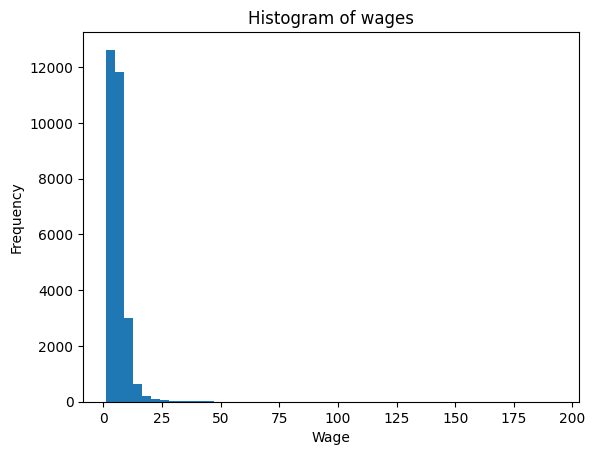

In [4]:
plt.hist(x = dataset["wage"],bins=50)
plt.ylabel("Frequency")
plt.xlabel("Wage")
plt.title("Histogram of wages")
plt.show()

<font size = "5" >

We can see similar outliers in age
- In this case a line would not produce a very good fit

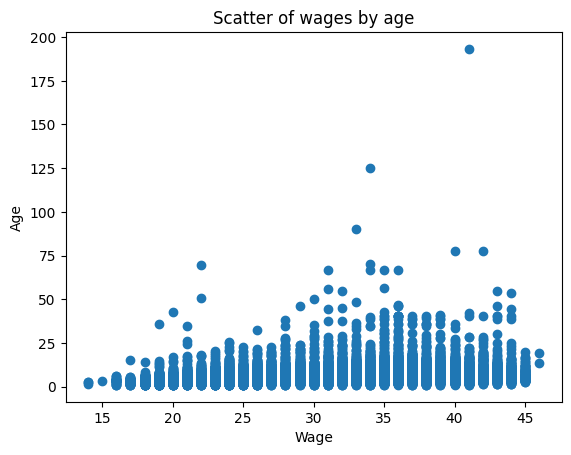

In [5]:
plt.scatter(x = dataset["age"],y = dataset["wage"])
plt.ylabel("Age")
plt.xlabel("Wage")
plt.title("Scatter of wages by age")
plt.show()

<font size = "5" >

### <span style="color:darkblue">  II. Poisson Regression </span>

The poisson regression assumes that 

$ \mathbb{E}[Y \mid X] = e^{\beta_0 + \beta_1X_1 + \beta_2X_2 + \cdots + \beta_K X_K }$

- Great way to model discrete count data
- Also great with heavy tailed data

In [6]:
# Construct data matrix
y, X = patsy.dmatrices(
    'wage ~ age + tenure ',
    dataset,
    return_type='dataframe'
)
y = np.ravel(y)

<font size = "5" >

Estimate model and generate raw regression table

In [7]:
poisson_model = sm.GLM(y, X, family=sm.families.Poisson()).fit(cov_type= "HC1")
poisson_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                28101
Model:                            GLM   Df Residuals:                    28098
Model Family:                 Poisson   Df Model:                            2
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -70425.
Date:                Thu, 15 Oct 2026   Deviance:                       41100.
Time:                        11:52:48   Pearson chi2:                 6.25e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2164
Covariance Type:                  HC1                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2349      0.018     68.579      0.000       1.200       1.270
age            0.0155      0.001     21.059      0.000       0.014       0.017
tenure         0.0312      0.001     29.934      0.000       0.029       0.033
==============================================================================
"""

<font size = "5" >

Generate formatted regression table

In [8]:
mt.ETable([poisson_model])

<maketables.mtable.MTable.__repr__.<locals>.DualOutput at 0x1a5aeeb8c50>

<font size = "5">

Try it yourself

- Explore the dataset
- Explore 3 or four different specifications of the Poisson model
- Practice including a factor, an interaction, and a polynomial <br>
(see Lecture 11)

In [12]:
# Write your own code

# Explore the dataset
# Explore 3 or four different specifications of the Poisson model
# Practice including a factor, an interaction, and a polynomial <br>
# (see Lecture 11)

dataset.head()
poisson_model2 = smf.glm(formula='wage ~ age + tenure + C(race)', data=dataset, family=sm.families.Poisson()).fit(cov_type="HC1")
poisson_model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                   wage   No. Observations:                28101
Model:                            GLM   Df Residuals:                    28096
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -70032.
Date:                Thu, 15 Oct 2026   Deviance:                       40313.
Time:                        11:55:12   Pearson chi2:                 6.11e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2380
Covariance Type:                  HC1                                         
================================================================================
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.2826      0.018     71.871      0.000       1.248       1.318
C(race)[T.2]    -0.1513      0.008    -19.643      0.000      -0.166      -0.136
C(race)[T.3]     0.0957      0.038      2.521      0.012       0.021       0.170
age              0.0152      0.001     20.759      0.000       0.014       0.017
tenure           0.0317      0.001     30.716      0.000       0.030       0.034
================================================================================
"""

<font size = "5">

Try it yourself

- Estimate your poisson model and a regression model using <br>
a training dataset
- Compute predictions for each model in a test dataset
- Which one performs better out-of-sample? You can use mean square error <br>
as a metric


In [18]:
# Write your own code


# Try it yourself

# - Estimate your poisson model and a regression model using a training dataset

train_data, test_data = train_test_split(dataset, test_size=0.2, random_state=42)
train_y, train_X = patsy.dmatrices(
    'wage ~ age + tenure + C(race)',
    train_data,
    return_type='dataframe'
)
train_y = np.ravel(train_y)

test_y, test_X = patsy.dmatrices(
    'wage ~ age + tenure + C(race)',
    test_data,
    return_type='dataframe'
)
test_y = np.ravel(test_y)

# - Compute predictions for each model in a test dataset

train_poisson_model = sm.GLM(train_y, train_X, family=sm.families.Poisson()).fit(cov_type= "HC1")
train_poisson_predictions = train_poisson_model.predict(train_X)
train_poisson_predictions_test = train_poisson_model.predict(test_X)

train_linear_model = sm.OLS(train_y, train_X).fit(cov_type= "HC1")
train_linear_predictions = train_linear_model.predict(train_X)


# Which one performs better out-of-sample? You can use mean square error as a metric

# The prediction that performs better out-of-sample is the one with the lower mean square error (MSE).
# You can calculate the MSE for each model's predictions on the test dataset and compare them to determine
# which model has better predictive performance.